# Classification Track
Preidicting if the room is occupied or not 

In [1]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
sns.set_theme(palette="colorblind")

In [2]:
df_train = pd.read_csv("../data/datatraining.txt")
df_test1 = pd.read_csv("../data/datatest.txt")
df_test2 = pd.read_csv("../data/datatest2.txt")
df1 = pd.concat([df_train,df_test1,df_test2])
nRow, nCol = df1.shape
print(f'There are {nRow} rows and {nCol} columns')

# Parse timestamps before performing time-based feature engineering
df1['date'] = pd.to_datetime(df1['date'], errors='coerce')

# Remove rows whose timestamp could not be parsed
df1 = df1.dropna(subset=['date']).copy()

# Number of seconds elapsed since midnight (0 to 86399)
df1['NSM'] = (
    df1['date'].dt.hour * 3600
    + df1['date'].dt.minute * 60
    + df1['date'].dt.second
)

# Boolean calendar features
df1['Weekday'] = (df1['date'].dt.dayofweek < 5)
df1['Weekend'] = (df1['date'].dt.dayofweek >= 5)

print(df1[['date', 'NSM', 'Weekday', 'Weekend']].head())
print('Invalid dates removed:', nRow - len(df1))

There are 20560 rows and 7 columns
                 date    NSM  Weekday  Weekend
1 2015-02-04 17:51:00  64260     True    False
2 2015-02-04 17:51:59  64319     True    False
3 2015-02-04 17:53:00  64380     True    False
4 2015-02-04 17:54:00  64440     True    False
5 2015-02-04 17:55:00  64500     True    False
Invalid dates removed: 0


In [3]:
print("Duplicate rows:", df1.duplicated().sum())
df1 = df1.drop_duplicates().reset_index(drop=True)

Duplicate rows: 0


In [4]:
df1.describe()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,NSM
count,20560,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000
mean,2015-02-10 13:42:06.146984448,20.906212,27.655925,130.756622,690.553276,0.004228,0.231031,42997.431031
min,2015-02-02 14:19:00,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000,0.000000
25%,2015-02-06 11:05:45,20.200000,24.500000,0.000000,460.000000,0.003719,0.000000,20520.000000
50%,2015-02-10 00:45:30,20.700000,27.290000,0.000000,565.416667,0.004292,0.000000,42480.000000
75%,2015-02-14 19:39:14.249999872,21.525000,31.290000,301.000000,804.666667,0.004832,0.000000,65819.000000
max,2015-02-18 09:19:00,24.408333,39.500000,1697.250000,2076.500000,0.006476,1.000000,86339.000000
std,NaN,1.055315,4.982154,210.430875,311.201281,0.000768,0.421503,25497.938212


In [5]:
df1.head(5)

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,NSM,Weekday,Weekend
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1,64260,True,False
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1,64319,True,False
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1,64380,True,False
3,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1,64440,True,False
4,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1,64500,True,False


In [6]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           20560 non-null  datetime64[ns]
 1   Temperature    20560 non-null  float64       
 2   Humidity       20560 non-null  float64       
 3   Light          20560 non-null  float64       
 4   CO2            20560 non-null  float64       
 5   HumidityRatio  20560 non-null  float64       
 6   Occupancy      20560 non-null  int64         
 7   NSM            20560 non-null  int32         
 8   Weekday        20560 non-null  bool          
 9   Weekend        20560 non-null  bool          
dtypes: bool(2), datetime64[ns](1), float64(5), int32(1), int64(1)
memory usage: 1.2 MB


In [7]:
for col in df1.columns:
    print("No.of na for ",col , ": ",df1[col].isna().sum())

No.of na for  date :  0
No.of na for  Temperature :  0
No.of na for  Humidity :  0
No.of na for  Light :  0
No.of na for  CO2 :  0
No.of na for  HumidityRatio :  0
No.of na for  Occupancy :  0
No.of na for  NSM :  0
No.of na for  Weekday :  0
No.of na for  Weekend :  0


# Distribution of Occupancy

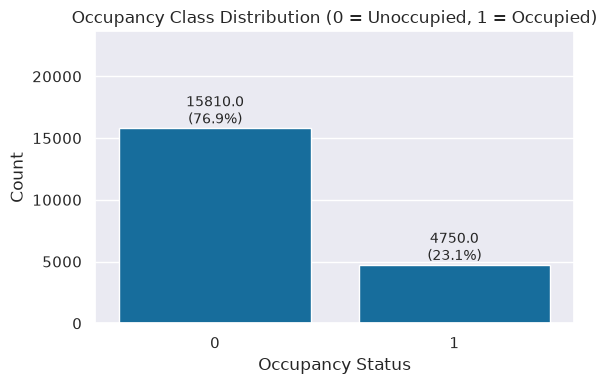

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df1, x='Occupancy')

# Add total count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height}\n({height/len(df1)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10)

plt.title('Occupancy Class Distribution (0 = Unoccupied, 1 = Occupied)')
plt.xlabel('Occupancy Status')
plt.ylabel('Count')
plt.ylim(0, len(df1) * 1.15)  # Add padding for labels
plt.tight_layout()
plt.show()

In [9]:
features = ["Temperature","Light","CO2","HumidityRatio"]

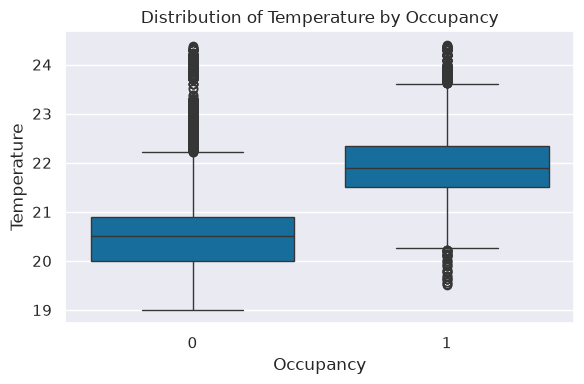

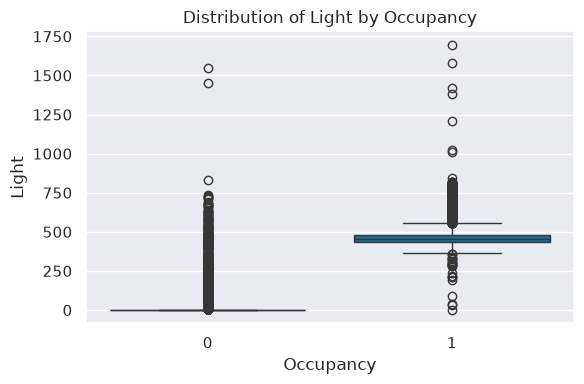

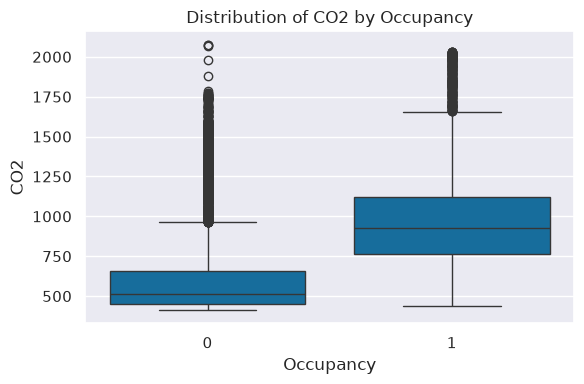

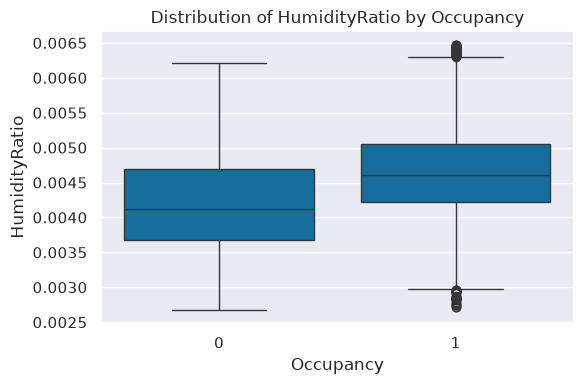

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define your feature columns explicitly (excluding target column)
features = ['Temperature', 'Light', 'CO2', 'HumidityRatio']

for col in features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df1, x='Occupancy', y=col)
    plt.title(f'Distribution of {col} by Occupancy')
    plt.tight_layout()
    plt.show()

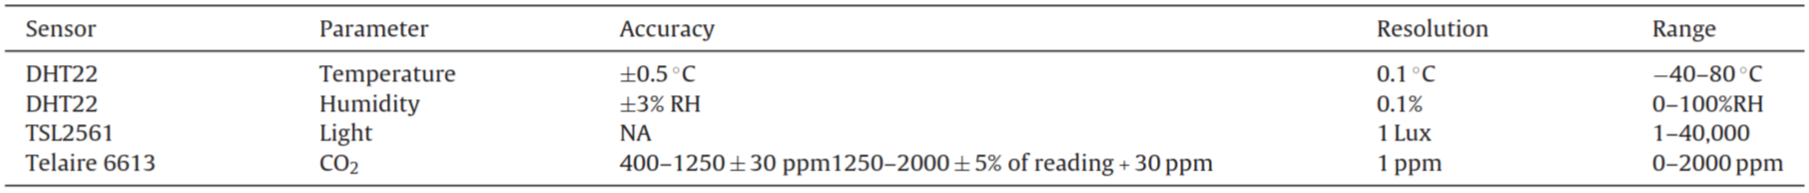
Sensors used to record 

Using the hardware specification, we note that the CO2 recodings, over 2000 are considered to be sensor anamolies hence we would be removing those records

In [11]:
def cleanData(df):
    return df.query('CO2 <= 2000').reset_index(drop=True)

# Distribution of Occupancy

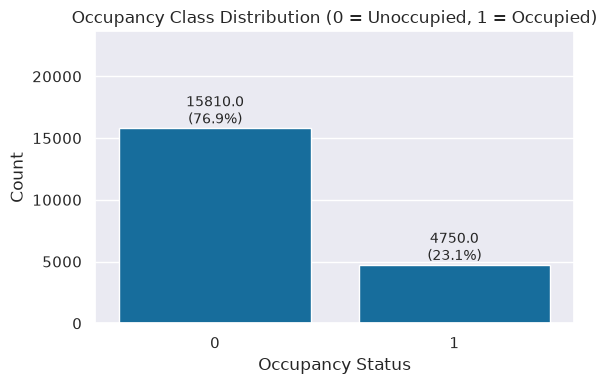

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df1, x='Occupancy')

# Add total count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height}\n({height/len(df1)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10)

plt.title('Occupancy Class Distribution (0 = Unoccupied, 1 = Occupied)')
plt.xlabel('Occupancy Status')
plt.ylabel('Count')
plt.ylim(0, len(df1) * 1.15)  # Add padding for labels
plt.tight_layout()
plt.show()

This shows class imbalance

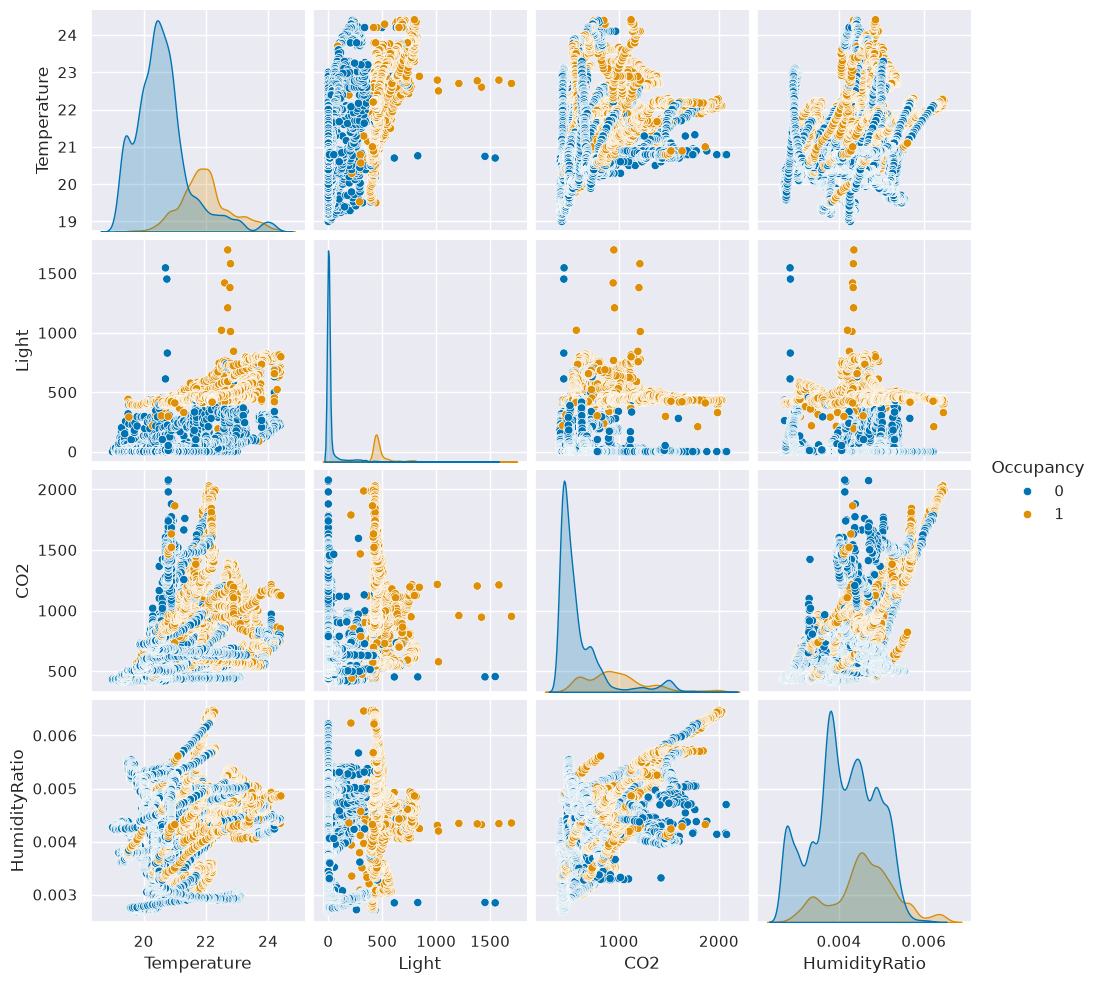

In [13]:
sns.pairplot(df1[features+["Occupancy"]],hue='Occupancy')

<Axes: >

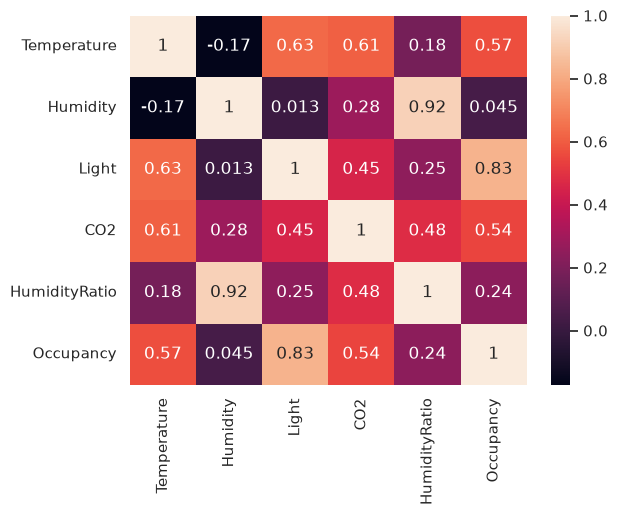

In [14]:
sns.heatmap(df1[["Temperature","Humidity","Light","CO2","HumidityRatio","Occupancy"]].corr(method='spearman'),annot=True)

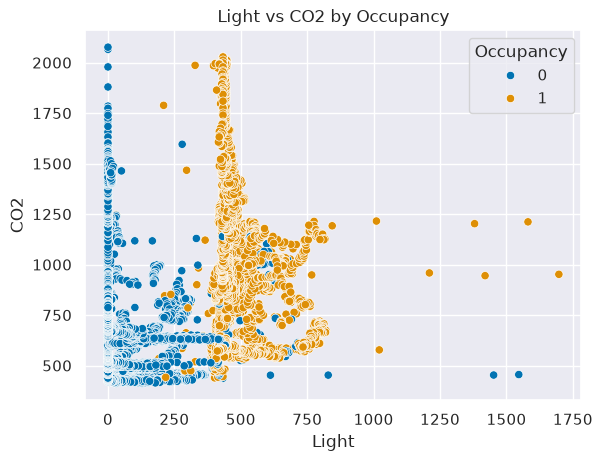

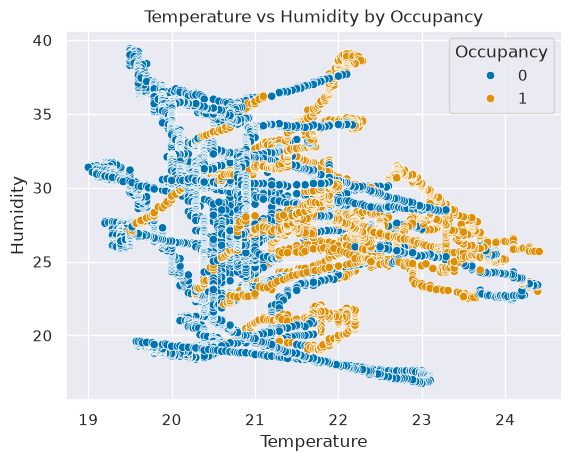

In [15]:
sns.scatterplot(data=df1, x="Light", y="CO2", hue="Occupancy")
plt.title("Light vs CO2 by Occupancy")
plt.show()

sns.scatterplot(data=df1, x="Temperature", y="Humidity", hue="Occupancy")
plt.title("Temperature vs Humidity by Occupancy")
plt.show()

In [16]:
features = ["Temperature","Humidity","Light","CO2","HumidityRatio"]
print(df1.groupby("Occupancy")[features].mean())
print(df1.groupby("Occupancy")[features].median())


           Temperature   Humidity       Light         CO2  HumidityRatio
Occupancy                                                               
0            20.584830  27.529654   25.237893  604.996614       0.004120
1            21.975909  28.076209  481.967380  975.321870       0.004589
           Temperature  Humidity  Light         CO2  HumidityRatio
Occupancy                                                         
0                20.50    27.150    0.0  511.000000       0.004127
1                21.89    27.882  454.0  928.583333       0.004603


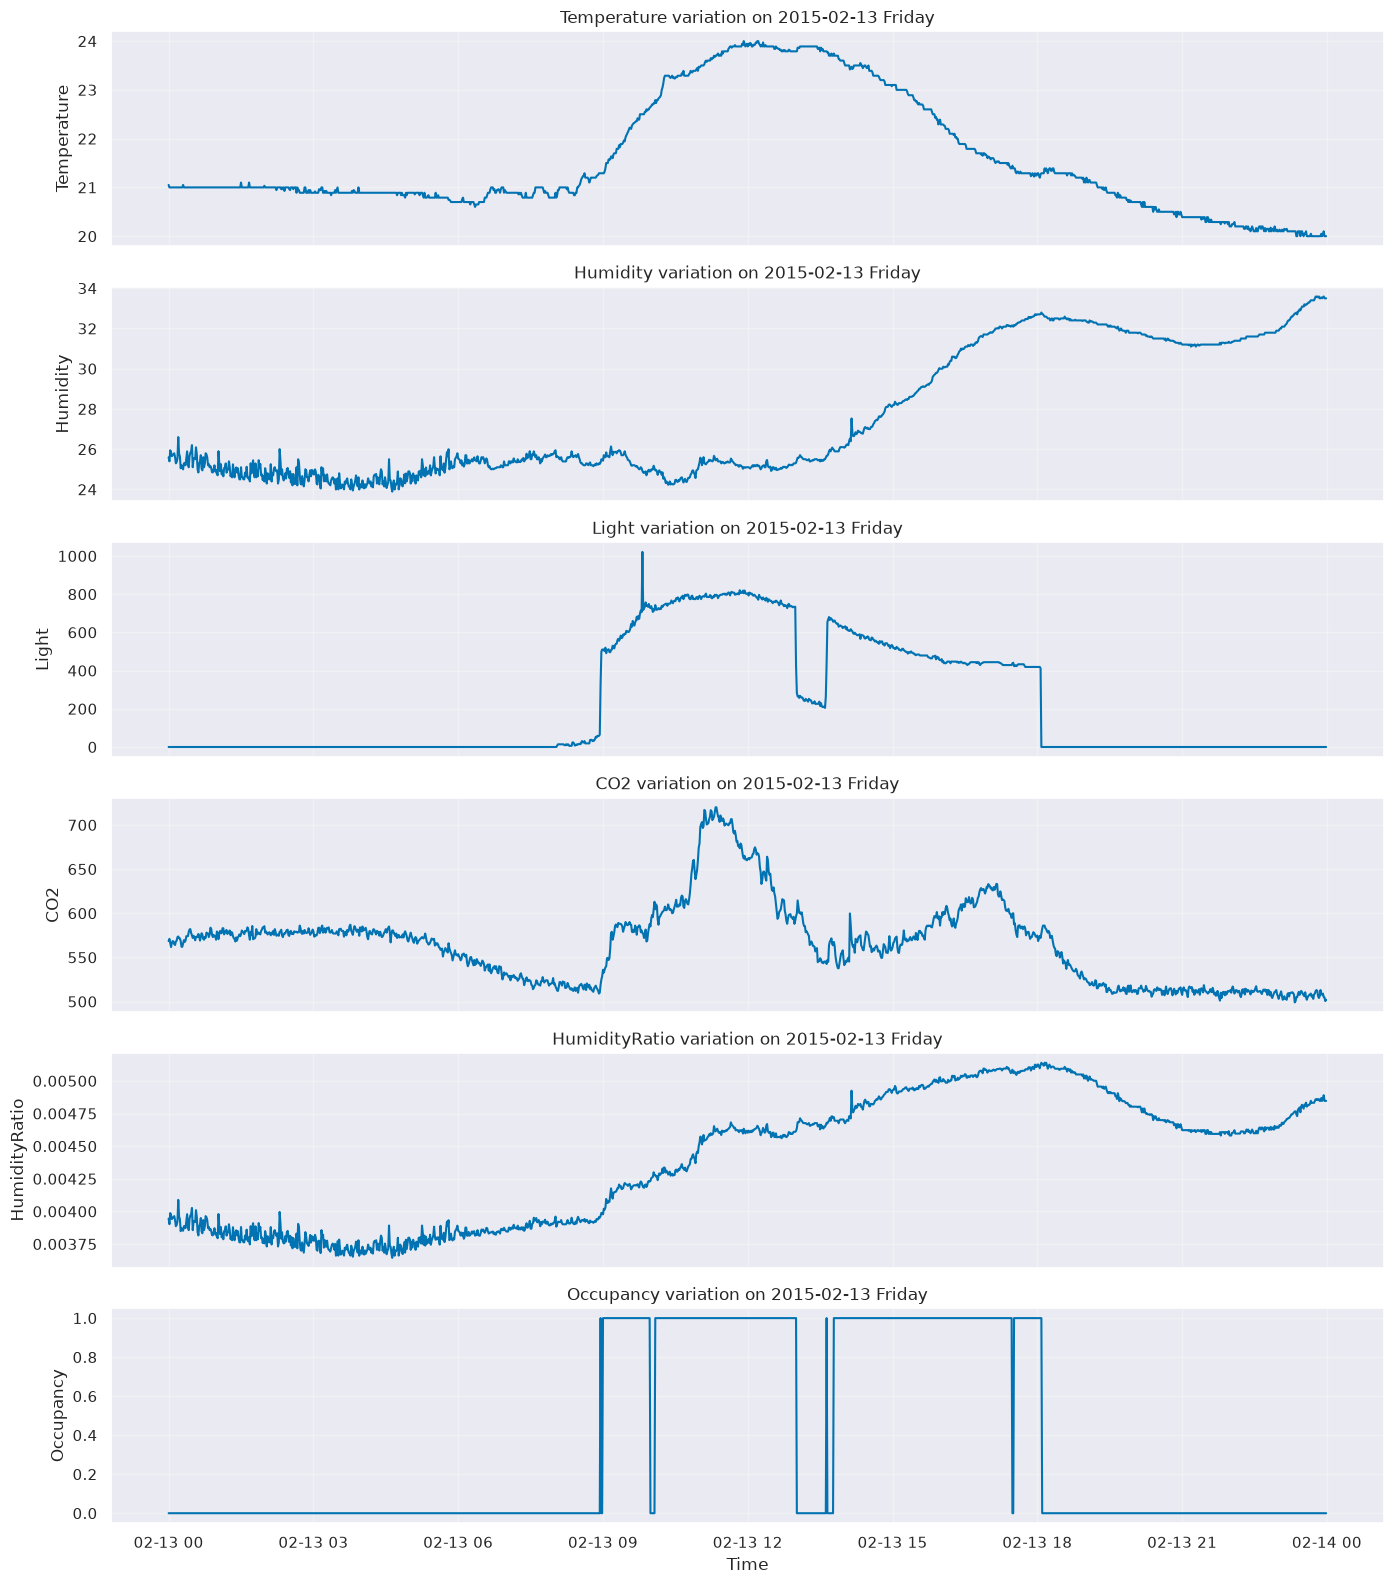

In [17]:
features = [
      "Temperature",
      "Humidity",
      "Light",
      "CO2",
      "HumidityRatio",
      "Occupancy"
  ]
df1["date"] = pd.to_datetime(df1["date"])

  # Select a specific date
selected_date = "2015-02-13"

day_data = df1[
  df1["date"].dt.date == pd.to_datetime(selected_date).date()
].copy()
  # Plot each feature against time
fig, axes = plt.subplots(
  len(features),
  1,
  figsize=(14, 16),
  sharex=True
)

for ax, feature in zip(axes, features):
  ax.plot(
      day_data["date"],
      day_data[feature],
      linewidth=1.5
  )
  ax.set_title(f"{feature} variation on {selected_date} "+ pd.to_datetime(selected_date).day_name())
  ax.set_ylabel(feature)
  ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

This plot visualaises the change of features on given date.
We are able to notice the fluctuation of the light, w.r.t to occupancy 

## Distribution of Temperature

<Axes: xlabel='Temperature', ylabel='Count'>

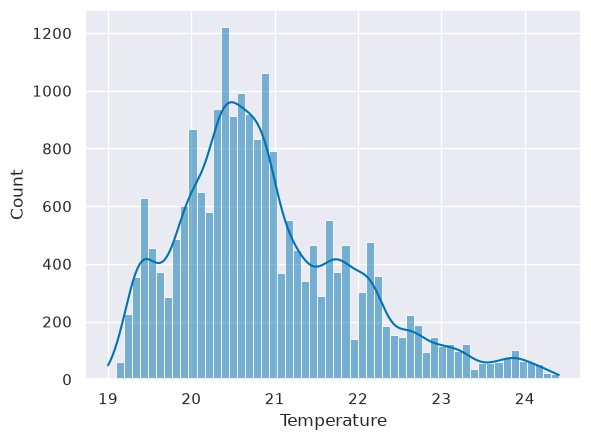

In [18]:
sns.histplot(df1.Temperature,kde=True)

## Distribution of Humidity Ratio

<Axes: xlabel='HumidityRatio', ylabel='Count'>

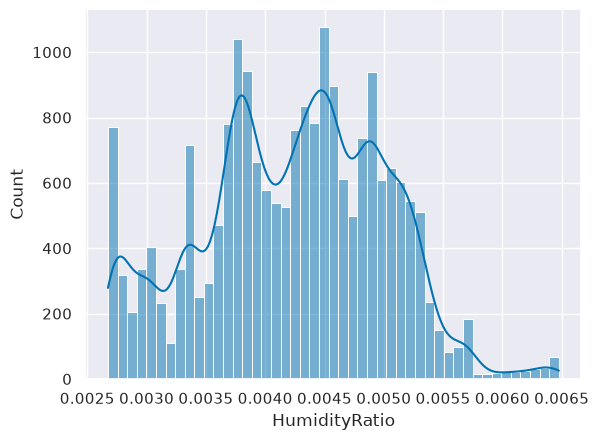

In [19]:
sns.histplot(df1.HumidityRatio,kde=True)

# Distribution of Light

<Axes: xlabel='Light', ylabel='Count'>

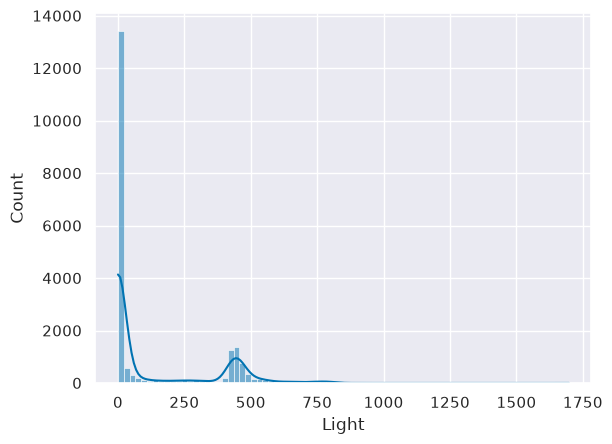

In [20]:
sns.histplot(df1.Light,kde=True)

# Distribution of CO2

<Axes: xlabel='CO2', ylabel='Count'>

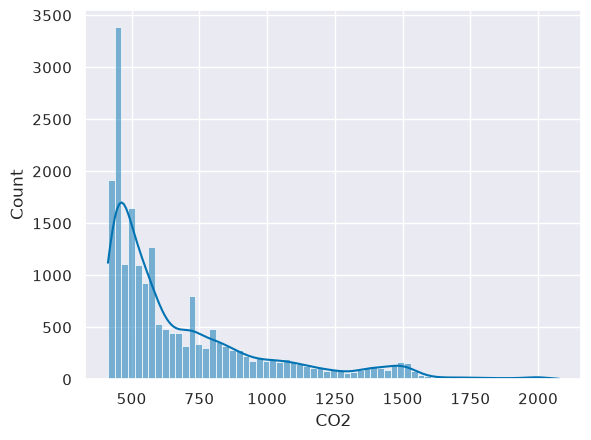

In [21]:
sns.histplot(df1.CO2,kde=True)

# Distribution of Temperature

<Axes: xlabel='Temperature', ylabel='Count'>

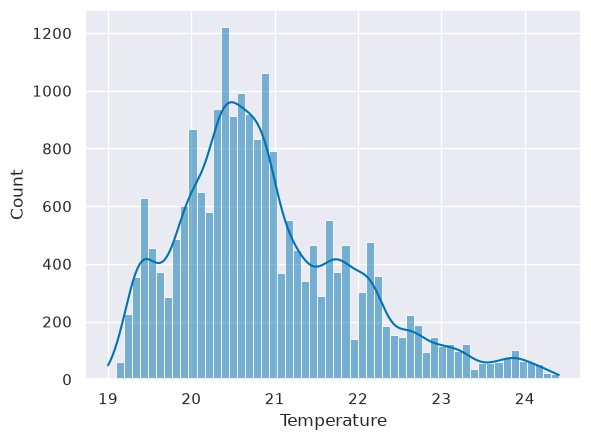

In [22]:
sns.histplot(df1.Temperature,kde=True)

# Feature Engineering

> Humidity ratio is also feature engineered by the dataset provider. This is used over humidity, to make humidity independent of temperature.
> This is calculated as <br>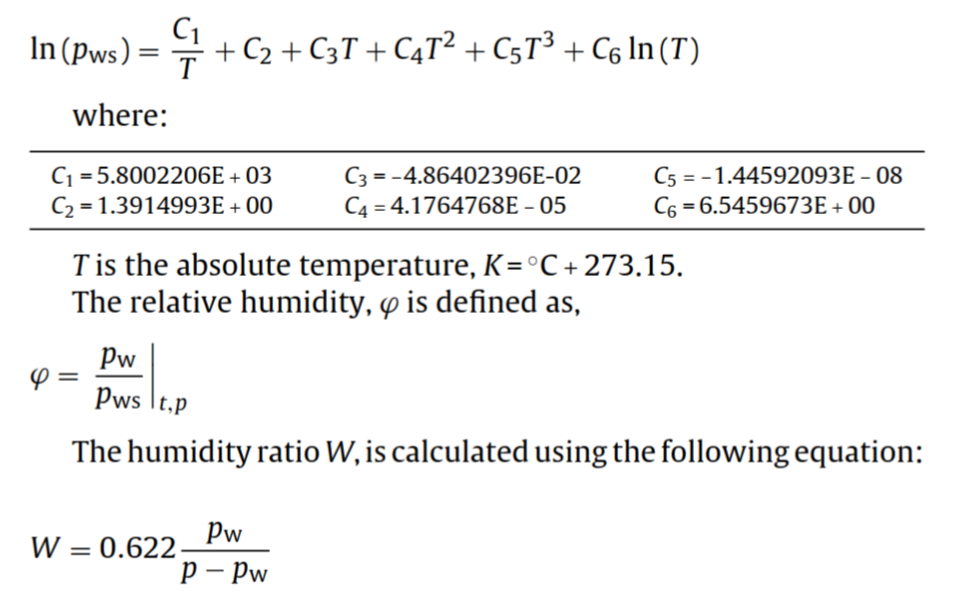

In [23]:
def prepareFeatures(df):
    df["date"] = pd.to_datetime(df["date"])
    
    # Seconds since midnight
    df["NSM"] = (
      df["date"].dt.hour * 3600
      + df["date"].dt.minute * 60
      + df["date"].dt.second
    )
    
    # True for Monday–Friday, False for Saturday–Sunday
    df["Weekday"] = df["date"].dt.dayofweek < 5
    
    # True for Saturday–Sunday, False otherwise
    df["Weekend"] = df["date"].dt.dayofweek >= 5
    
    df[["date", "NSM", "Weekday", "Weekend"]].head()

# Training the model

In [27]:
from sklearn.model_selection import train_test_split
target = "Occupancy"
features = [
  "Temperature",
  "Light",
  "CO2",
  "HumidityRatio",
  "NSM",
  "Weekday",
  "Weekend"
]


train = pd.read_csv("../data/datatraining.txt")
test1 = pd.read_csv("../data/datatest.txt")
test2 = pd.read_csv("../data/datatest2.txt")

test = pd.concat([test1,test2])

test = cleanData(test)
train = cleanData(train)
prepareFeatures(test)
prepareFeatures(train)
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]


print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

Training set: (8102, 7)
Testing set: (12414, 7)

Training class distribution:
Occupancy
0    0.791656
1    0.208344
Name: proportion, dtype: float64


=== Logistic Regression ===
Best Params: {'clf__C': 10.0, 'clf__solver': 'lbfgs'}
Best CV weighted F1: 0.9887
Test Accuracy: 0.9904
Test Weighted F1: 0.9905

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      9393
           1       0.97      0.99      0.98      3021

    accuracy                           0.99     12414
   macro avg       0.98      0.99      0.99     12414
weighted avg       0.99      0.99      0.99     12414



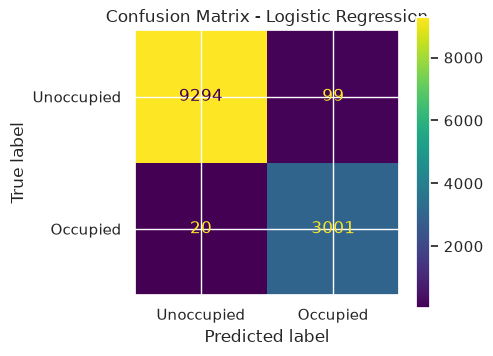

=== K-Nearest Neighbors ===
Best Params: {'clf__metric': 'manhattan', 'clf__n_neighbors': 19}
Best CV weighted F1: 0.9593
Test Accuracy: 0.9741
Test Weighted F1: 0.9741

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9393
           1       0.94      0.95      0.95      3021

    accuracy                           0.97     12414
   macro avg       0.96      0.97      0.96     12414
weighted avg       0.97      0.97      0.97     12414



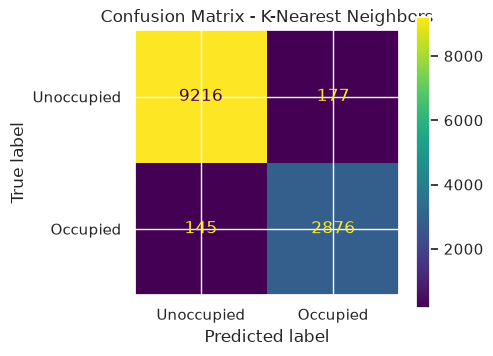

=== Naive Bayes (Gaussian) ===
Best Params: {'clf__var_smoothing': np.float64(0.0001)}
Best CV weighted F1: 0.9807
Test Accuracy: 0.9820
Test Weighted F1: 0.9822

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      9393
           1       0.93      1.00      0.96      3021

    accuracy                           0.98     12414
   macro avg       0.97      0.99      0.98     12414
weighted avg       0.98      0.98      0.98     12414



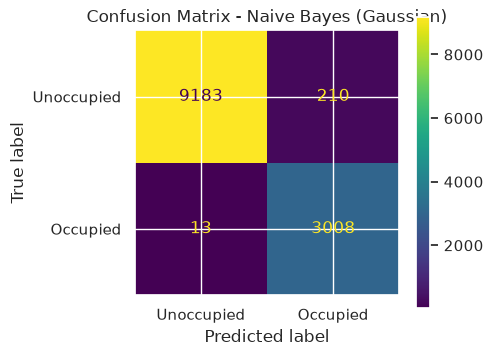

=== Decision Tree ===
Best Params: {'clf__criterion': 'entropy', 'clf__max_depth': 3}
Best CV weighted F1: 0.9731
Test Accuracy: 0.9385
Test Weighted F1: 0.9377

              precision    recall  f1-score   support

           0       0.95      0.97      0.96      9393
           1       0.91      0.83      0.87      3021

    accuracy                           0.94     12414
   macro avg       0.93      0.90      0.91     12414
weighted avg       0.94      0.94      0.94     12414



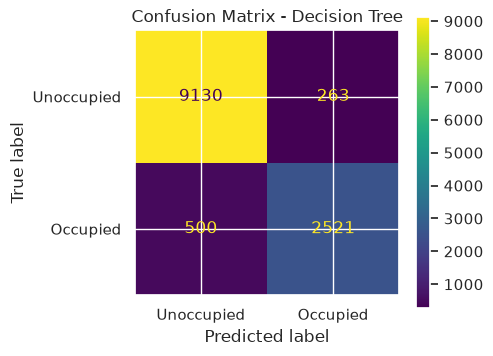

=== Support Vector Machine ===
Best Params: {'clf__C': 0.1, 'clf__kernel': 'linear'}
Best CV weighted F1: 0.9885
Test Accuracy: 0.9877
Test Weighted F1: 0.9878

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      9393
           1       0.95      1.00      0.98      3021

    accuracy                           0.99     12414
   macro avg       0.98      0.99      0.98     12414
weighted avg       0.99      0.99      0.99     12414



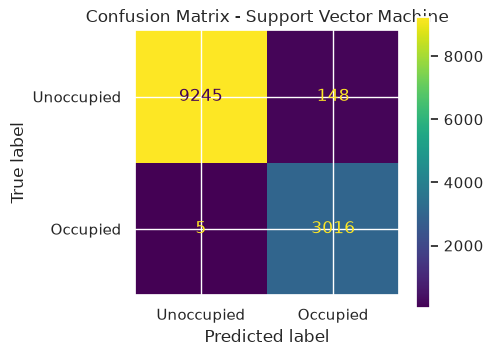

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pipe_logreg = Pipeline([
    ('scaler', RobustScaler()),
    ('clf', LogisticRegression(random_state=42, max_iter=1000))
])

pipe_knn = Pipeline([
    ('scaler', RobustScaler()),
    ('clf', KNeighborsClassifier())
])

pipe_gnb = Pipeline([
    ('scaler', RobustScaler()),
    ('clf', GaussianNB())
])

pipe_dt = Pipeline([
    ('clf', DecisionTreeClassifier(random_state=42))
])

pipe_svc = Pipeline([
    ('scaler', RobustScaler()),
    ('clf', SVC(random_state=42))
])

param_grids = {
    "Logistic Regression": {
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__solver': ['lbfgs']
    },
    "K-Nearest Neighbors": {
        'clf__n_neighbors': [1, 3, 5, 7, 11, 15, 17, 19],
        'clf__metric': ['euclidean', 'manhattan']
    },
    "Naive Bayes (Gaussian)": {
        'clf__var_smoothing': np.logspace(0, -9, num=10)
    },
    "Decision Tree": {
        'clf__max_depth': [3, 5, 7, 10, None],
        'clf__criterion': ['gini', 'entropy']
    },
    "Support Vector Machine": {
        'clf__C': [0.1, 1.0, 10.0],
        'clf__kernel': ['rbf', 'linear', 'poly']
    }
}

pipelines = {
    "Logistic Regression": pipe_logreg,
    "K-Nearest Neighbors": pipe_knn,
    "Naive Bayes (Gaussian)": pipe_gnb,
    "Decision Tree": pipe_dt,
    "Support Vector Machine": pipe_svc
}

best_models = {}

for name, pipe in pipelines.items():
    grid = GridSearchCV(
        estimator=pipe, 
        param_grid=param_grids[name], 
        cv=5, 
        scoring='f1_weighted', 
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_
    best_models[name] = best_model
    
    y_pred = best_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    weighted_f1 = f1_score(y_test, y_pred, average="weighted")
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"=== {name} ===")
    print(f"Best Params: {grid.best_params_}")
    print(f"Best CV weighted F1: {grid.best_score_:.4f}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Test Weighted F1: {weighted_f1:.4f}\n")
    print(classification_report(y_test, y_pred))
    
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Unoccupied", "Occupied"]
    ).plot(ax=ax)
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [85]:
results_data = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    
    # Extract training grid score
    cv_f1 = grid_search_results[name].best_score_ if 'grid_search_results' in locals() else np.nan
    
    acc = accuracy_score(y_test, y_pred)
    test_f1 = f1_score(y_test, y_pred, average="weighted")
    
    results_data.append({
        "Model": name,
        "Best Params": str(model.get_params()['clf']),
        "Test Accuracy": f"{acc:.4f}",
        "Test Weighted F1": f"{test_f1:.4f}"
    })

comparison_df = pd.DataFrame(results_data)
comparison_df

,Model,Best Params,Test Accuracy,Test Weighted F1
0,Logistic Regression,"LogisticRegression(C=10.0, max_iter=1000, rand...",0.9904,0.9905
1,K-Nearest Neighbors,"KNeighborsClassifier(metric='manhattan', n_nei...",0.9741,0.9741
2,Naive Bayes (Gaussian),GaussianNB(var_smoothing=np.float64(0.0001)),0.9820,0.9822
3,Decision Tree,"DecisionTreeClassifier(criterion='entropy', ma...",0.9385,0.9377
4,Support Vector Machine,"SVC(C=0.1, kernel='linear', random_state=42)",0.9877,0.9878
